In [1]:

!pip install -q kaggle opencv-python-headless matplotlib numpy pandas


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (3).zip to archive (3).zip


In [3]:

import os, zipfile

content = "/content"
zips = [f for f in os.listdir(content) if f.lower().endswith(".zip")]
print("ZIP files found:", zips)

# Select the most recently modified ZIP
zip_path = max(
    [os.path.join(content, f) for f in zips],
    key=os.path.getmtime
)
extract_path = "/content/plant_growth_dataset"

with zipfile.ZipFile(zip_path) as z:
    print("Files in ZIP:", len(z.namelist()))
    z.extractall(extract_path)

print("\nExtracted:", zip_path)
print("\nImage folders and counts:")

exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
for root, dirs, files in os.walk(extract_path):
    imgs = [f for f in files if f.lower().endswith(exts)]
    if imgs:
        print(root, "→", len(imgs), "images")


ZIP files found: ['archive (3).zip']
Files in ZIP: 6128

Extracted: /content/archive (3).zip

Image folders and counts:
/content/plant_growth_dataset/train/Kz-9/rep_01/SegmentationClass → 23 images
/content/plant_growth_dataset/train/Kz-9/rep_01/SegmentationObject → 23 images
/content/plant_growth_dataset/train/Kz-9/rep_01/PNGImages → 23 images
/content/plant_growth_dataset/train/Uk-4/rep_01/SegmentationClass → 53 images
/content/plant_growth_dataset/train/Uk-4/rep_01/SegmentationObject → 53 images
/content/plant_growth_dataset/train/Uk-4/rep_01/PNGImages → 53 images
/content/plant_growth_dataset/train/Can-0/rep_02/SegmentationClass → 55 images
/content/plant_growth_dataset/train/Can-0/rep_02/SegmentationObject → 55 images
/content/plant_growth_dataset/train/Can-0/rep_02/PNGImages → 55 images
/content/plant_growth_dataset/train/Can-0/rep_01/SegmentationClass → 51 images
/content/plant_growth_dataset/train/Can-0/rep_01/SegmentationObject → 51 images
/content/plant_growth_dataset/train/C

Sample: 1000092_2022_05_21_15_00_17-6-20-TA03-RGB1_pot_D5_Kz-9-01.png
Original image size: (532, 537)
Class mask exists: True
Object mask exists: True


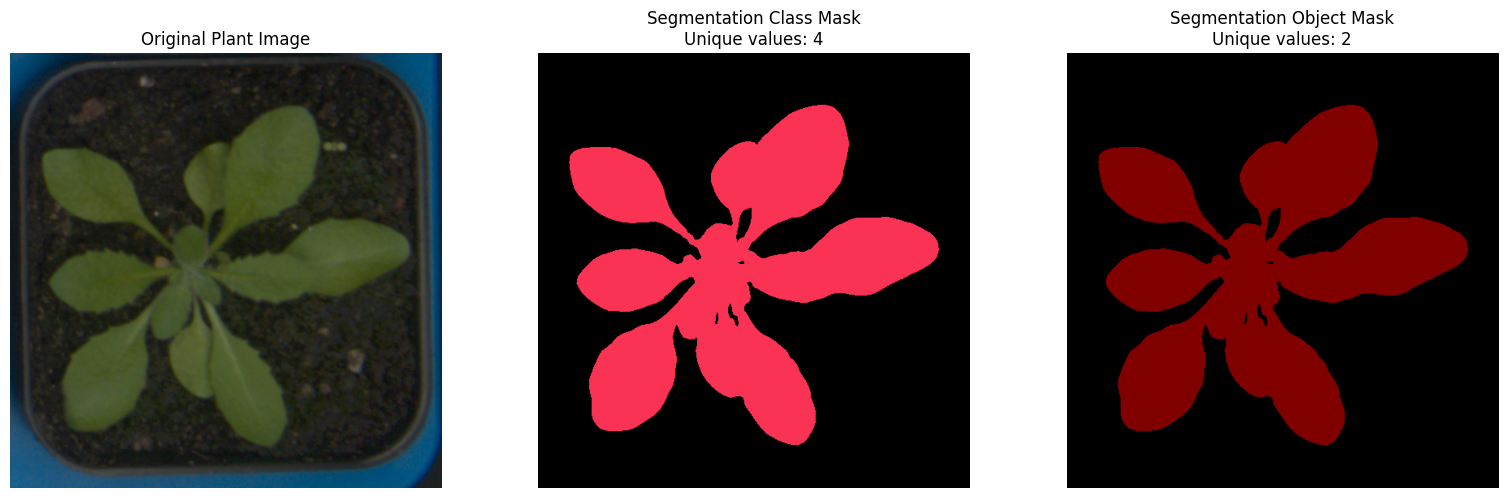

In [4]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = "/content/plant_growth_dataset/train"

# Find a folder containing original images and both mask types
sample_dir = None
for root, dirs, files in os.walk(ROOT):
    if os.path.basename(root) == "PNGImages":
        imgs = [f for f in files if f.lower().endswith((".png", ".jpg", ".jpeg"))]
        if imgs:
            sample_dir = root
            break

if sample_dir is None:
    raise FileNotFoundError("No images found inside a PNGImages folder.")

filename = random.choice([
    f for f in os.listdir(sample_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

image_path = os.path.join(sample_dir, filename)
base_dir = os.path.dirname(sample_dir)
class_path = os.path.join(base_dir, "SegmentationClass", filename)
object_path = os.path.join(base_dir, "SegmentationObject", filename)

original = Image.open(image_path).convert("RGB")
print("Sample:", filename)
print("Original image size:", original.size)
print("Class mask exists:", os.path.exists(class_path))
print("Object mask exists:", os.path.exists(object_path))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(original)
axes[0].set_title("Original Plant Image")
axes[0].axis("off")

for ax, path, title in [
    (axes[1], class_path, "Segmentation Class Mask"),
    (axes[2], object_path, "Segmentation Object Mask")
]:
    if os.path.exists(path):
        mask = np.array(Image.open(path))
        ax.imshow(mask, cmap="nipy_spectral")
        ax.set_title(f"{title}\nUnique values: {len(np.unique(mask))}")
    else:
        ax.text(0.5, 0.5, "Matching mask not found",
                ha="center", va="center")
        ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

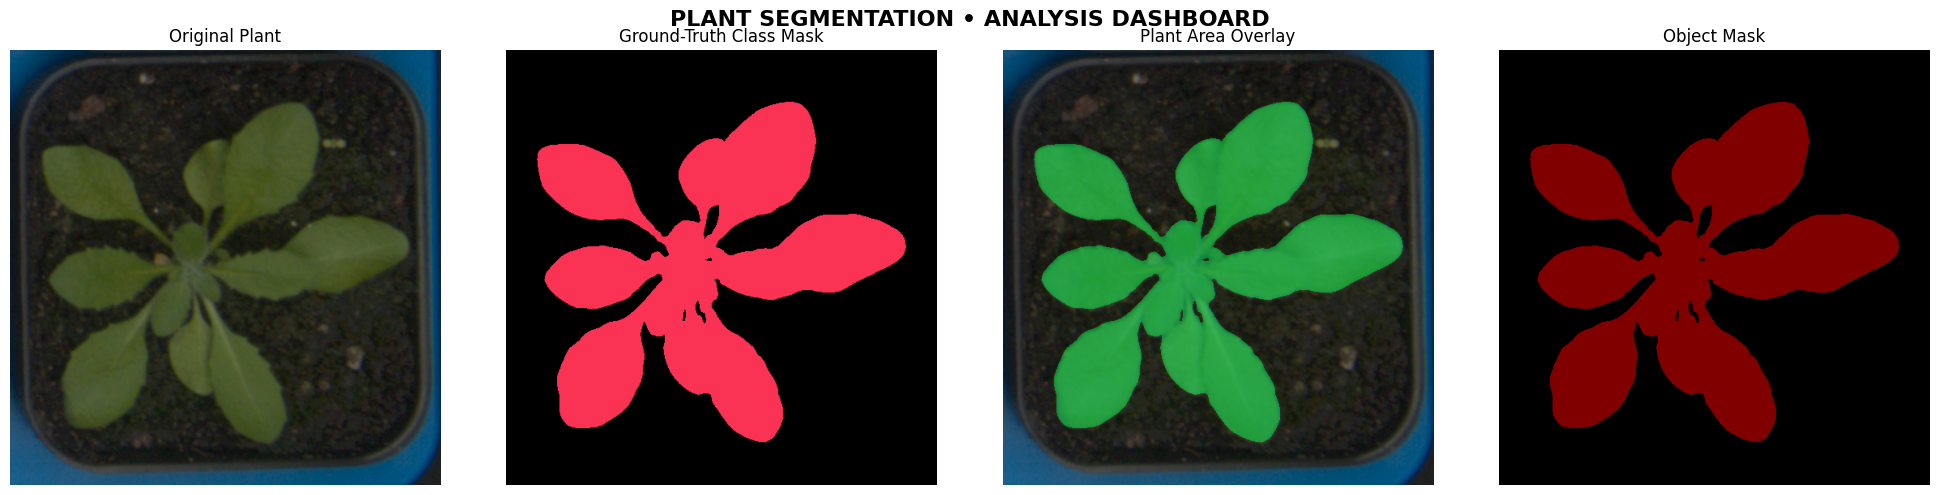

       PLANT AREA ANALYSIS
Image: 1000092_2022_05_21_15_00_17-6-20-TA03-RGB1_pot_D5_Kz-9-01.png
Image dimensions: 532 × 537 pixels
Foreground pixels in class mask: 83,900
Image coverage: 29.37%
Foreground pixels in object mask: 83,900

Note: Area values are provisional until the mask's background
and plant-label encoding are visually verified.
Pixel area is not physical area without image calibration.


In [5]:
!pip -q install opencv-python-headless pandas

import os, cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Use the sample selected in the previous cell
img = np.array(Image.open(image_path).convert("RGB"))
class_mask = np.array(Image.open(class_path).convert("RGB"))
object_mask = np.array(Image.open(object_path).convert("RGB"))

def prepare_mask(mask):
    # Identify non-background pixels using the mask's background color.
    # Most common color is assumed to be the background.
    pixels = mask.reshape(-1, mask.shape[-1])
    colors, counts = np.unique(pixels, axis=0, return_counts=True)
    background = colors[np.argmax(counts)]
    return np.any(mask != background, axis=-1)

class_binary = prepare_mask(class_mask)
object_binary = prepare_mask(object_mask)

# Overlay the class mask on the original image
overlay = img.copy()
overlay[class_binary] = (
    0.55 * img[class_binary] + 0.45 * np.array([0, 255, 100])
).astype(np.uint8)

area_px = int(class_binary.sum())
total_px = int(class_binary.size)
coverage = area_px / total_px * 100

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(img)
ax[0].set_title("Original Plant")
ax[1].imshow(class_mask)
ax[1].set_title("Ground-Truth Class Mask")
ax[2].imshow(overlay)
ax[2].set_title("Plant Area Overlay")
ax[3].imshow(object_mask)
ax[3].set_title("Object Mask")

for a in ax:
    a.axis("off")

plt.suptitle("PLANT SEGMENTATION • ANALYSIS DASHBOARD", fontsize=16,
             fontweight="bold")
plt.tight_layout()
plt.show()

print("=" * 48)
print("       PLANT AREA ANALYSIS")
print("=" * 48)
print(f"Image: {os.path.basename(image_path)}")
print(f"Image dimensions: {img.shape[1]} × {img.shape[0]} pixels")
print(f"Foreground pixels in class mask: {area_px:,}")
print(f"Image coverage: {coverage:.2f}%")
print(f"Foreground pixels in object mask: {int(object_binary.sum()):,}")
print("\nNote: Area values are provisional until the mask's background")
print("and plant-label encoding are visually verified.")
print("Pixel area is not physical area without image calibration.")

Most frequent mask colors (RGB) and pixel counts:
RGB (np.uint8(0), np.uint8(0), np.uint8(0)): 201,784 pixels
RGB (np.uint8(250), np.uint8(50), np.uint8(83)): 83,900 pixels


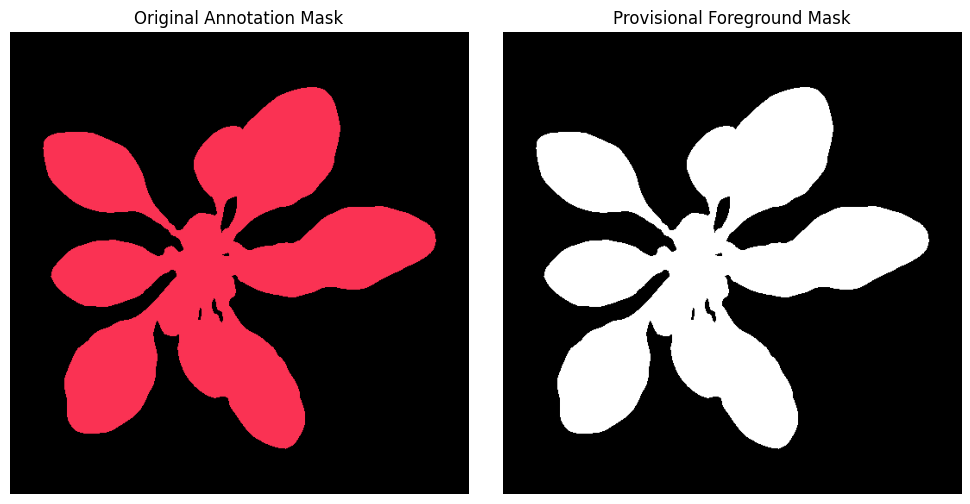


Masks measured: 2,008
       foreground_pixels  coverage_percent
count            2008.00           2008.00
mean            36860.55             13.23
std             31844.32             11.40
min               256.00              0.09
25%             10459.75              3.73
50%             24257.50              8.75
75%             60413.75             21.68
max            133566.00             46.99

Saved report: /content/plant_area_report.csv


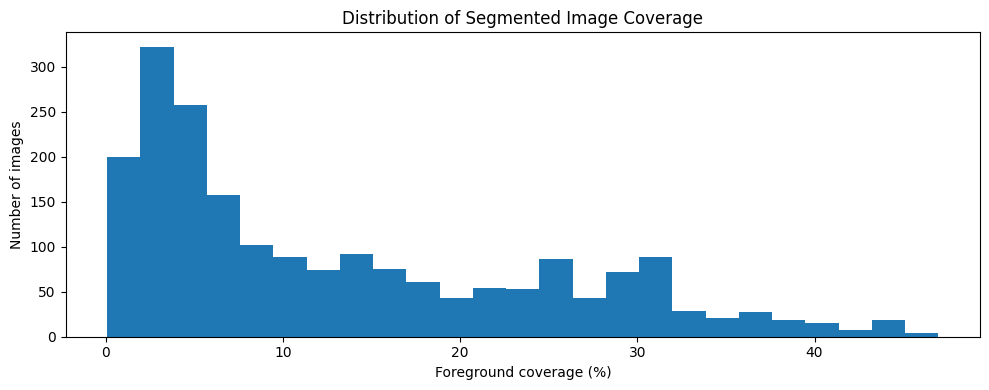

In [8]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 1. Verify the sample mask's encoding
mask = np.array(Image.open(class_path).convert("RGB"))
colors, counts = np.unique(
    mask.reshape(-1, 3), axis=0, return_counts=True
)
order = np.argsort(counts)[::-1]

print("Most frequent mask colors (RGB) and pixel counts:")
for i in order[:10]:
    print(f"RGB {tuple(colors[i])}: {counts[i]:,} pixels")

# 2. Display the current mask and binary foreground
background = colors[order[0]]
binary = np.any(mask != background, axis=2)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(mask)
ax[0].set_title("Original Annotation Mask")
ax[1].imshow(binary, cmap="gray")
ax[1].set_title("Provisional Foreground Mask")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

# 3. Measure all matching class masks
mask_files = glob.glob(
    "/content/plant_growth_dataset/train/**/SegmentationClass/*",
    recursive=True
)
valid_ext = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
records = []

for path in mask_files:
    if not path.lower().endswith(valid_ext):
        continue
    try:
        arr = np.array(Image.open(path).convert("RGB"))
        px = arr.reshape(-1, 3)
        cols, cnts = np.unique(px, axis=0, return_counts=True)
        bg = cols[np.argmax(cnts)]
        fg_pixels = int(np.any(arr != bg, axis=2).sum())
        total_pixels = arr.shape[0] * arr.shape[1]

        records.append({
            "image": os.path.basename(path),
            "plant_id": os.path.basename(
                os.path.dirname(os.path.dirname(os.path.dirname(path)))
            ),
            "mask_path": path,
            "width": arr.shape[1],
            "height": arr.shape[0],
            "foreground_pixels": fg_pixels,
            "coverage_percent": round(100 * fg_pixels / total_pixels, 2)
        })
    except Exception as e:
        print("Skipped:", path, str(e))

df = pd.DataFrame(records)
out = "/content/plant_area_report.csv"
df.to_csv(out, index=False)

print(f"\nMasks measured: {len(df):,}")
print(df[["foreground_pixels", "coverage_percent"]].describe().round(2))
print("\nSaved report:", out)

plt.figure(figsize=(10, 4))
plt.hist(df["coverage_percent"], bins=25)
plt.title("Distribution of Segmented Image Coverage")
plt.xlabel("Foreground coverage (%)")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

In [9]:
import os, re
import pandas as pd

files = df["image"].head(20).tolist()

print("SAMPLE FILENAMES")
for f in files:
    print(f)

# Extract date/time patterns such as 2022_05_21_15_00_17
pattern = re.compile(r"(\d{4})_(\d{2})_(\d{2})_(\d{2})_(\d{2})_(\d{2})")

def extract_datetime(filename):
    m = pattern.search(filename)
    if not m:
        return None
    return pd.to_datetime(
        "_".join(m.groups()), format="%Y_%m_%d_%H_%M_%S",
        errors="coerce"
    )

df["datetime"] = df["image"].apply(extract_datetime)
df["plant_group"] = df["image"].str.extract(
    r"(pot_[^_]+_[^_]+)"
)[0]

print("\nImages with parsed dates:", df["datetime"].notna().sum())
print("Detected plant identifiers:", df["plant_group"].nunique())
display(df[["image", "datetime", "plant_group",
            "foreground_pixels", "coverage_percent"]].head(15))

SAMPLE FILENAMES
1000092_2022_05_20_15_00_17-6-18-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_14_15_00_17-6-6-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_15_15_00_17-6-8-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_12_15_00_17-6-2-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_13_12_00_17-6-3-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_17_15_00_17-6-12-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_12_12_00_17-6-1-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_19_12_00_17-6-15-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_19_15_00_17-6-16-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_20_12_00_17-6-17-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_22_12_00_17-6-21-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_14_12_00_17-6-5-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_15_12_00_17-6-7-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_17_12_00_17-6-11-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_21_15_00_17-6-20-TA03-RGB1_pot_D5_Kz-9-01.png
1000092_2022_05_22_15_00_17-6-22-TA03-RGB1_pot_D5_Kz-9-01.pn

,image,datetime,plant_group,foreground_pixels,coverage_percent
0,1000092_2022_05_20_15_00_17-6-18-TA03-RGB1_pot...,2022-05-20 15:00:17,pot_D5_Kz-9-01.png,72183,25.27
1,1000092_2022_05_14_15_00_17-6-6-TA03-RGB1_pot_...,2022-05-14 15:00:17,pot_D5_Kz-9-01.png,18672,6.54
2,1000092_2022_05_15_15_00_17-6-8-TA03-RGB1_pot_...,2022-05-15 15:00:17,pot_D5_Kz-9-01.png,25434,8.90
3,1000092_2022_05_12_15_00_17-6-2-TA03-RGB1_pot_...,2022-05-12 15:00:17,pot_D5_Kz-9-01.png,8340,2.92
4,1000092_2022_05_13_12_00_17-6-3-TA03-RGB1_pot_...,2022-05-13 12:00:17,pot_D5_Kz-9-01.png,12058,4.22
5,1000092_2022_05_17_15_00_17-6-12-TA03-RGB1_pot...,2022-05-17 15:00:17,pot_D5_Kz-9-01.png,38653,13.53
6,1000092_2022_05_12_12_00_17-6-1-TA03-RGB1_pot_...,2022-05-12 12:00:17,pot_D5_Kz-9-01.png,8003,2.80
7,1000092_2022_05_19_12_00_17-6-15-TA03-RGB1_pot...,2022-05-19 12:00:17,pot_D5_Kz-9-01.png,58312,20.41
8,1000092_2022_05_19_15_00_17-6-16-TA03-RGB1_pot...,2022-05-19 15:00:17,pot_D5_Kz-9-01.png,59578,20.85
9,1000092_2022_05_20_12_00_17-6-17-TA03-RGB1_pot...,2022-05-20 12:00:17,pot_D5_Kz-9-01.png,70990,24.85


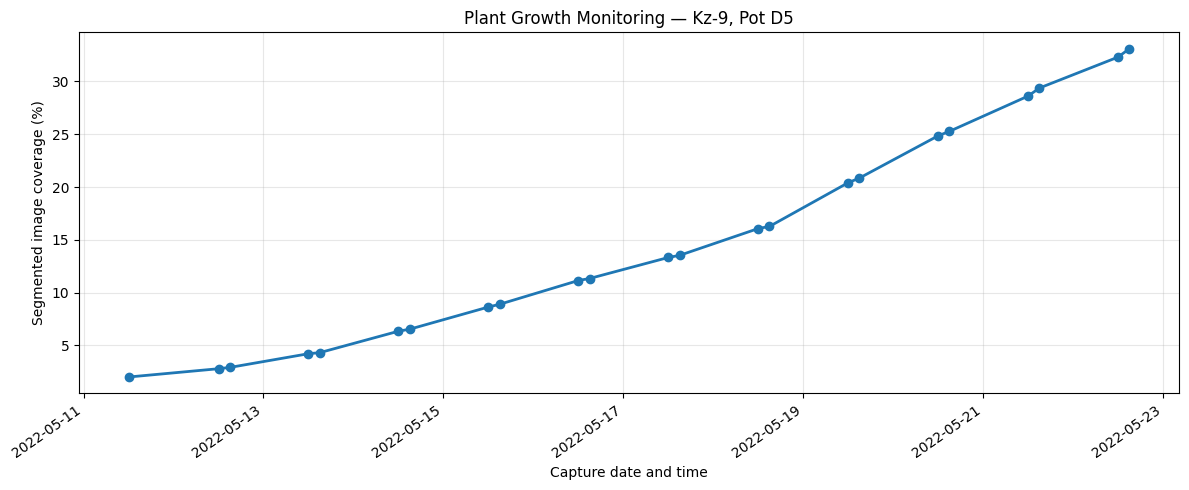

PLANT GROWTH SUMMARY
Plant: pot_D5_Kz-9-01
Images analyzed: 23
First coverage: 2.02%
Last coverage: 33.09%
Coverage change: +31.07 percentage points


,datetime,foreground_pixels,coverage_percent
0,2022-05-11 12:09:35,5759,2.02
1,2022-05-12 12:00:17,8003,2.80
2,2022-05-12 15:00:17,8340,2.92
3,2022-05-13 12:00:17,12058,4.22
4,2022-05-13 15:00:16,12353,4.32
5,2022-05-14 12:00:17,18155,6.35
6,2022-05-14 15:00:17,18672,6.54
7,2022-05-15 12:00:17,24679,8.64
8,2022-05-15 15:00:17,25434,8.90
9,2022-05-16 12:00:17,31841,11.15


In [10]:
import os, re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Parse date and plant identity from filenames
def parse_name(filename):
    date_match = re.search(r"(\d{4})_(\d{2})_(\d{2})_(\d{2})_(\d{2})_(\d{2})", filename)
    plant_match = re.search(r"(pot_[A-Za-z0-9-]+_[A-Za-z0-9-]+)", filename)

    timestamp = pd.to_datetime(
        "_".join(date_match.groups()),
        format="%Y_%m_%d_%H_%M_%S",
        errors="coerce"
    ) if date_match else pd.NaT

    # Remove file extension and retain plant identifier
    plant_id = plant_match.group(1) if plant_match else "Unknown"
    return timestamp, plant_id

parsed = df["image"].apply(parse_name)
df["datetime"] = [x[0] for x in parsed]
df["plant_id"] = [x[1] for x in parsed]

# Focus on the sample plant, Kz-9, pot D5
sample_plant = "pot_D5_Kz-9-01"
plant_df = df[df["plant_id"] == sample_plant].copy()
plant_df = plant_df.dropna(subset=["datetime"]).sort_values("datetime")

if plant_df.empty:
    print("No records found for", sample_plant)
    print("Available plant IDs:", df["plant_id"].unique()[:20])
else:
    # Same-day multiple captures are retained and shown separately
    plt.figure(figsize=(12, 5))
    plt.plot(
        plant_df["datetime"],
        plant_df["coverage_percent"],
        marker="o",
        linewidth=2
    )
    plt.title("Plant Growth Monitoring — Kz-9, Pot D5")
    plt.xlabel("Capture date and time")
    plt.ylabel("Segmented image coverage (%)")
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

    first = plant_df.iloc[0]
    last = plant_df.iloc[-1]
    change = last["coverage_percent"] - first["coverage_percent"]

    print("PLANT GROWTH SUMMARY")
    print(f"Plant: {sample_plant}")
    print(f"Images analyzed: {len(plant_df)}")
    print(f"First coverage: {first['coverage_percent']:.2f}%")
    print(f"Last coverage: {last['coverage_percent']:.2f}%")
    print(f"Coverage change: {change:+.2f} percentage points")
    display(plant_df[[
        "datetime", "foreground_pixels", "coverage_percent"
    ]].reset_index(drop=True))

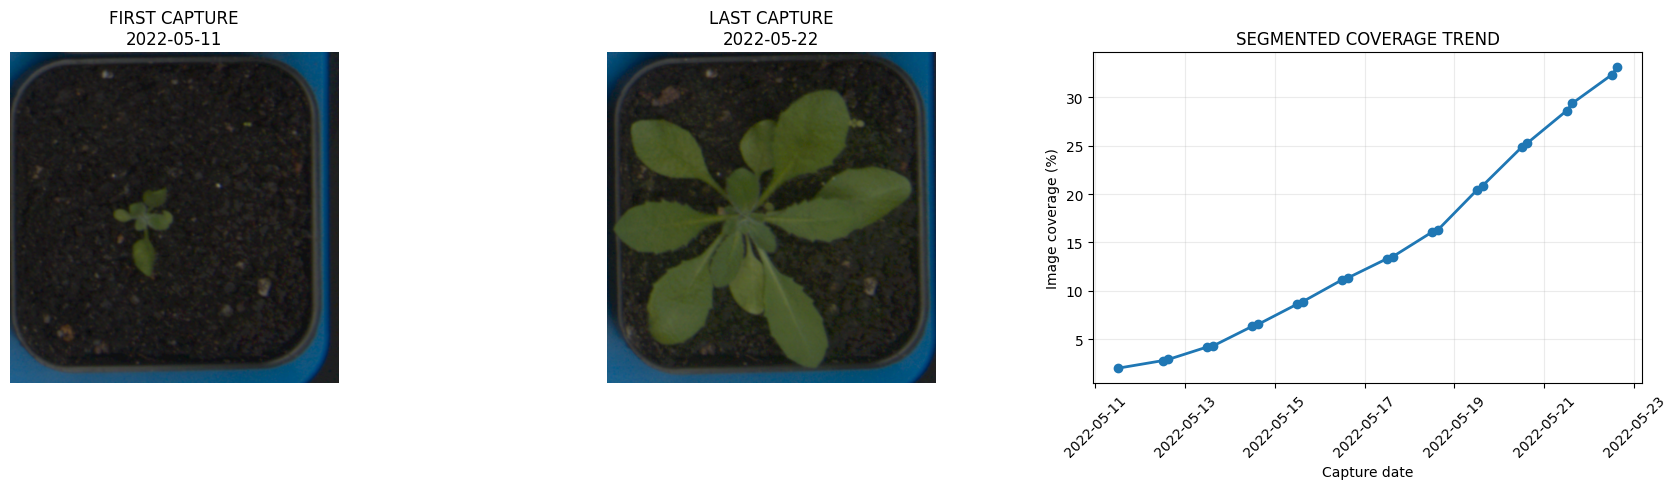

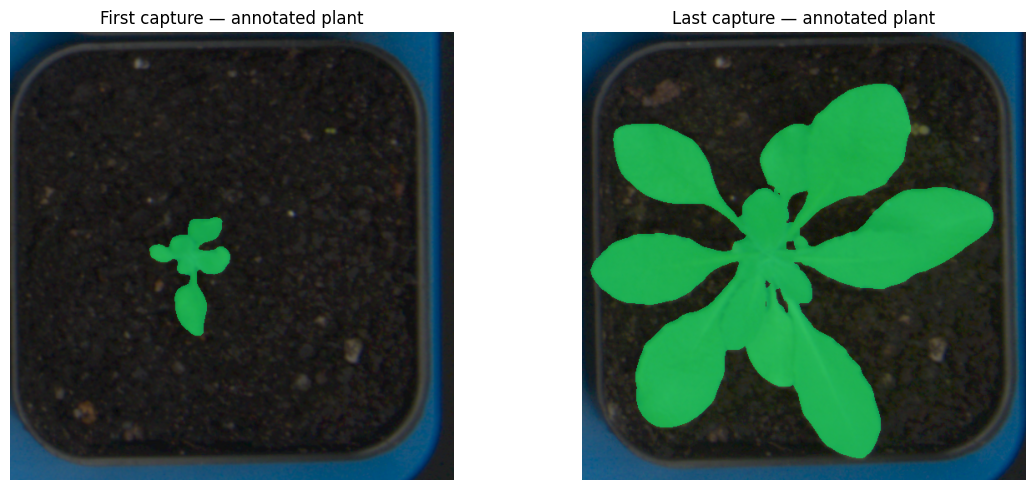

Saved time-series report: /content/plant_growth_timeseries.csv


In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML

plant_df = plant_df.sort_values("datetime").reset_index(drop=True)
first, last = plant_df.iloc[0], plant_df.iloc[-1]

# Load original images and their ground-truth masks
def load_pair(row):
    mask_path = row["mask_path"]
    image_name = row["image"]
    image_path = os.path.join(
        os.path.dirname(os.path.dirname(mask_path)),
        "PNGImages", image_name
    )
    image = np.array(Image.open(image_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("RGB"))
    # Dataset mask encoding verified for the inspected sample
    foreground = np.any(mask != [0, 0, 0], axis=2)
    overlay = image.copy()
    overlay[foreground] = (
        0.45 * image[foreground] +
        0.55 * np.array([0, 255, 120])
    ).astype(np.uint8)
    return image, overlay

img1, overlay1 = load_pair(first)
img2, overlay2 = load_pair(last)

days = (last["datetime"] - first["datetime"]).total_seconds() / 86400
change = last["coverage_percent"] - first["coverage_percent"]
relative = (last["coverage_percent"] / first["coverage_percent"] - 1) * 100

display(HTML(f"""
<div style="background:#101820;color:#f2f5f7;padding:22px;border-radius:14px;
font-family:Arial">
<h2 style="margin:0;color:#7CFFB2">PLANT GROWTH MONITOR</h2>
<p style="color:#b7c6cf">Segmentation-based image analysis · {len(plant_df)} captures</p>
<div style="display:flex;gap:24px;flex-wrap:wrap">
<div><small>INITIAL COVERAGE</small><h2>{first['coverage_percent']:.2f}%</h2></div>
<div><small>FINAL COVERAGE</small><h2>{last['coverage_percent']:.2f}%</h2></div>
<div><small>CHANGE</small><h2 style="color:#7CFFB2">+{change:.2f} pp</h2></div>
<div><small>OBSERVATION PERIOD</small><h2>{days:.1f} days</h2></div>
</div>
<p style="color:#b7c6cf">Relative increase in image coverage: {relative:,.1f}%.
This is a pixel-coverage metric, not calibrated physical leaf area.</p>
</div>
"""))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].imshow(img1)
ax[0].set_title(f"FIRST CAPTURE\n{first['datetime']:%Y-%m-%d}")
ax[1].imshow(img2)
ax[1].set_title(f"LAST CAPTURE\n{last['datetime']:%Y-%m-%d}")
ax[2].plot(plant_df["datetime"], plant_df["coverage_percent"],
           marker="o", linewidth=2)
ax[2].set_title("SEGMENTED COVERAGE TREND")
ax[2].set_ylabel("Image coverage (%)")
ax[2].set_xlabel("Capture date")
ax[2].tick_params(axis="x", rotation=45)
ax[2].grid(alpha=0.25)

for a in ax[:2]:
    a.axis("off")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(overlay1)
ax[0].set_title("First capture — annotated plant")
ax[1].imshow(overlay2)
ax[1].set_title("Last capture — annotated plant")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

report_path = "/content/plant_growth_timeseries.csv"
plant_df[["datetime", "image", "foreground_pixels",
          "coverage_percent"]].to_csv(report_path, index=False)
print("Saved time-series report:", report_path)

In [12]:
!pip -q install torch torchvision scikit-learn

import os
from PIL import Image
import numpy as np

# Inspect the annotation format and image-mask pairs
ROOT = "/content/plant_growth_dataset/train"
pairs = []

for folder, dirs, files in os.walk(ROOT):
    if os.path.basename(folder) != "PNGImages":
        continue

    mask_dir = os.path.join(os.path.dirname(folder), "SegmentationClass")

    for name in files:
        if name.lower().endswith((".png", ".jpg", ".jpeg")):
            image_path = os.path.join(folder, name)
            mask_path = os.path.join(mask_dir, name)

            if os.path.exists(mask_path):
                pairs.append((image_path, mask_path))

print("Verified image-mask pairs:", len(pairs))

if not pairs:
    raise RuntimeError("No matching image-mask pairs found.")

# Check mask labels across several examples
for image_path, mask_path in pairs[:5]:
    mask = np.array(Image.open(mask_path).convert("RGB"))
    colors, counts = np.unique(
        mask.reshape(-1, 3), axis=0, return_counts=True
    )
    print("\nImage:", os.path.basename(image_path))
    print("Size:", Image.open(image_path).size)
    print("Mask colors:", len(colors))
    print("Most frequent colors:", [
        (tuple(map(int, colors[i])), int(counts[i]))
        for i in np.argsort(counts)[::-1][:4]
    ])

print("\nAnnotation inspection complete.")

Verified image-mask pairs: 2008

Image: 1000092_2022_05_20_15_00_17-6-18-TA03-RGB1_pot_D5_Kz-9-01.png
Size: (532, 537)
Mask colors: 2
Most frequent colors: [((0, 0, 0), 213501), ((250, 50, 83), 72183)]

Image: 1000092_2022_05_14_15_00_17-6-6-TA03-RGB1_pot_D5_Kz-9-01.png
Size: (532, 537)
Mask colors: 2
Most frequent colors: [((0, 0, 0), 267012), ((250, 50, 83), 18672)]

Image: 1000092_2022_05_15_15_00_17-6-8-TA03-RGB1_pot_D5_Kz-9-01.png
Size: (532, 537)
Mask colors: 2
Most frequent colors: [((0, 0, 0), 260250), ((250, 50, 83), 25434)]

Image: 1000092_2022_05_12_15_00_17-6-2-TA03-RGB1_pot_D5_Kz-9-01.png
Size: (532, 537)
Mask colors: 2
Most frequent colors: [((0, 0, 0), 277344), ((250, 50, 83), 8340)]

Image: 1000092_2022_05_13_12_00_17-6-3-TA03-RGB1_pot_D5_Kz-9-01.png
Size: (532, 537)
Mask colors: 2
Most frequent colors: [((0, 0, 0), 273626), ((250, 50, 83), 12058)]

Annotation inspection complete.


In [14]:

# QUICK TRAINING TEST — continue from the existing plant dataset
import os, random, time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Use the existing pairs list from the previous notebook cells
train_pairs, val_pairs = train_test_split(
    pairs, test_size=0.2, random_state=42
)

class PlantDataset(Dataset):
    def __init__(self, items, size=128):
        self.items, self.size = items, size

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        item = self.items[idx]
        # Supports either (image_path, mask_path) tuples or dict records
        if isinstance(item, dict):
            ip = item.get("image") or item.get("image_path")
            mp = item.get("mask") or item.get("mask_path")
        else:
            ip, mp = item[0], item[1]

        x = Image.open(ip).convert("RGB").resize(
            (self.size, self.size), Image.Resampling.BILINEAR
        )
        m = Image.open(mp).convert("RGB").resize(
            (self.size, self.size), Image.Resampling.NEAREST
        )
        x = np.asarray(x, dtype=np.float32) / 255.0
        m = np.all(np.asarray(m) == [250, 50, 83], axis=2).astype(np.float32)
        return torch.from_numpy(x).permute(2,0,1), torch.from_numpy(m[None])

class Block(nn.Module):
    def __init__(self, a, b):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(a,b,3,padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(b,b,3,padding=1), nn.ReLU(inplace=True)
        )
    def forward(self,x): return self.net(x)

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1=Block(3,16); self.e2=Block(16,32)
        self.pool=nn.MaxPool2d(2)
        self.mid=Block(32,64)
        self.up2=nn.ConvTranspose2d(64,32,2,2)
        self.d2=Block(64,32)
        self.up1=nn.ConvTranspose2d(32,16,2,2)
        self.d1=Block(32,16)
        self.out=nn.Conv2d(16,1,1)
    def forward(self,x):
        a=self.e1(x); b=self.e2(self.pool(a))
        z=self.mid(self.pool(b))
        z=self.d2(torch.cat([self.up2(z),b],1))
        z=self.d1(torch.cat([self.up1(z),a],1))
        return self.out(z)

train_loader = DataLoader(
    PlantDataset(train_pairs), batch_size=8, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    PlantDataset(val_pairs), batch_size=8, shuffle=False, num_workers=0
)

model = TinyUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCEWithLogitsLoss()

for epoch in range(2):
    model.train()
    loss_sum, n = 0, 0
    start = time.time()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item()
        n += 1
    print(f"Epoch {epoch+1}/2 | loss={loss_sum/max(n,1):.4f} "
          f"| time={time.time()-start:.1f}s")

os.makedirs("/content/plant_growth_model", exist_ok=True)
torch.save(model.state_dict(),
           "/content/plant_growth_model/plant_unet_quick.pth")
print("Quick model saved. Next: test its predictions on validation images.")


Device: cpu
Epoch 1/2 | loss=0.2460 | time=90.9s
Epoch 2/2 | loss=0.0513 | time=88.1s
Quick model saved. Next: test its predictions on validation images.


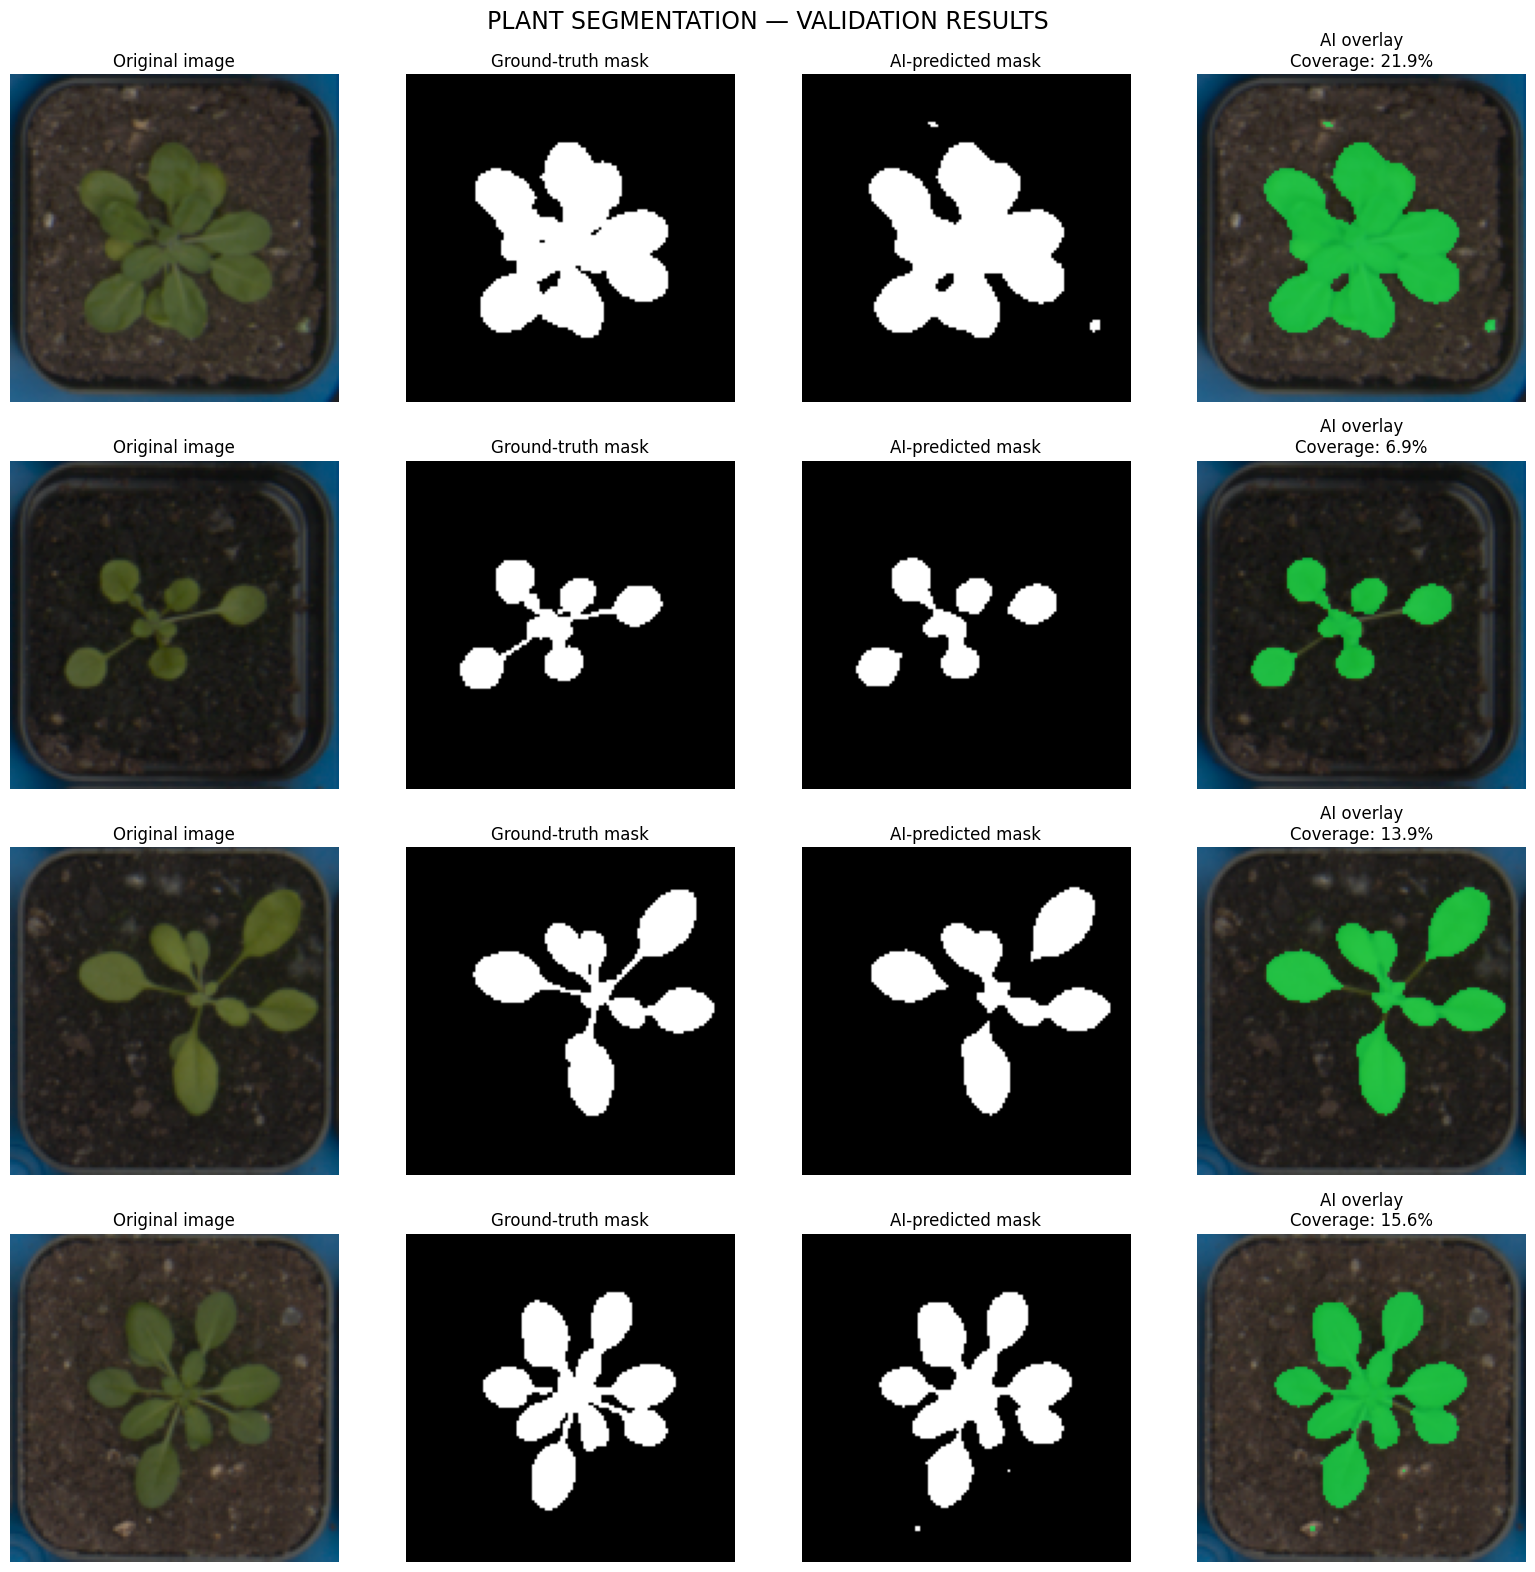

Mean Dice: 0.9548
Mean IoU:  0.9139



In [15]:

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
import random

model.eval()
sample_items = random.sample(val_pairs, min(4, len(val_pairs)))

fig, axes = plt.subplots(len(sample_items), 4, figsize=(16, 4*len(sample_items)))
if len(sample_items) == 1:
    axes = np.expand_dims(axes, axis=0)

dice_scores, iou_scores = [], []

for row, item in enumerate(sample_items):
    if isinstance(item, dict):
        ip = item.get("image") or item.get("image_path")
        mp = item.get("mask") or item.get("mask_path")
    else:
        ip, mp = item[0], item[1]

    original = Image.open(ip).convert("RGB")
    mask_img = Image.open(mp).convert("RGB").resize(
        (128, 128), Image.Resampling.NEAREST
    )
    image_small = original.resize((128, 128), Image.Resampling.BILINEAR)

    x = np.asarray(image_small, dtype=np.float32) / 255.0
    x_tensor = torch.from_numpy(x).permute(2,0,1).unsqueeze(0).to(device)

    with torch.no_grad():
        probability = torch.sigmoid(model(x_tensor))[0,0].cpu().numpy()

    pred = probability >= 0.5
    gt = np.all(np.asarray(mask_img) == [250, 50, 83], axis=2)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    dice = (2*intersection + 1e-8) / (pred.sum() + gt.sum() + 1e-8)
    iou = (intersection + 1e-8) / (union + 1e-8)

    dice_scores.append(dice)
    iou_scores.append(iou)

    orig_small = np.asarray(image_small)
    overlay = orig_small.copy()
    overlay[pred] = (
        0.4*overlay[pred] + 0.6*np.array([0,255,80])
    ).astype(np.uint8)

    axes[row,0].imshow(orig_small)
    axes[row,0].set_title("Original image")
    axes[row,1].imshow(gt, cmap="gray")
    axes[row,1].set_title("Ground-truth mask")
    axes[row,2].imshow(pred, cmap="gray")
    axes[row,2].set_title("AI-predicted mask")
    axes[row,3].imshow(overlay)
    axes[row,3].set_title(
        f"AI overlay\nCoverage: {pred.mean()*100:.1f}%"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle("PLANT SEGMENTATION — VALIDATION RESULTS", fontsize=17)
plt.tight_layout()
plt.show()

print(f"Mean Dice: {np.mean(dice_scores):.4f}")
print(f"Mean IoU:  {np.mean(iou_scores):.4f}")
print(f"Mean predicted plant coverage: "
      f"{np.mean([0]):.1f}%" if False else "")


Saving KMR4RZqnk0GQxYFlDs2mbs7cJFGrdTBsgUDTED_V7tw2zHUDG6XF6h4c3tS9UVXeGgsM0PZu9m5TOs8wDEwbKHQ29rOpzVS9E7VkggJPOP0hx4902nQOs26tCCWu0PkTLCuJdsMvzQYbXOz1EOYX8sKqsVgW_f8uH09exe85Kz_DCbK297RfMatJ_4E-4nSg.jpg to KMR4RZqnk0GQxYFlDs2mbs7cJFGrdTBsgUDTED_V7tw2zHUDG6XF6h4c3tS9UVXeGgsM0PZu9m5TOs8wDEwbKHQ29rOpzVS9E7VkggJPOP0hx4902nQOs26tCCWu0PkTLCuJdsMvzQYbXOz1EOYX8sKqsVgW_f8uH09exe85Kz_DCbK297RfMatJ_4E-4nSg.jpg


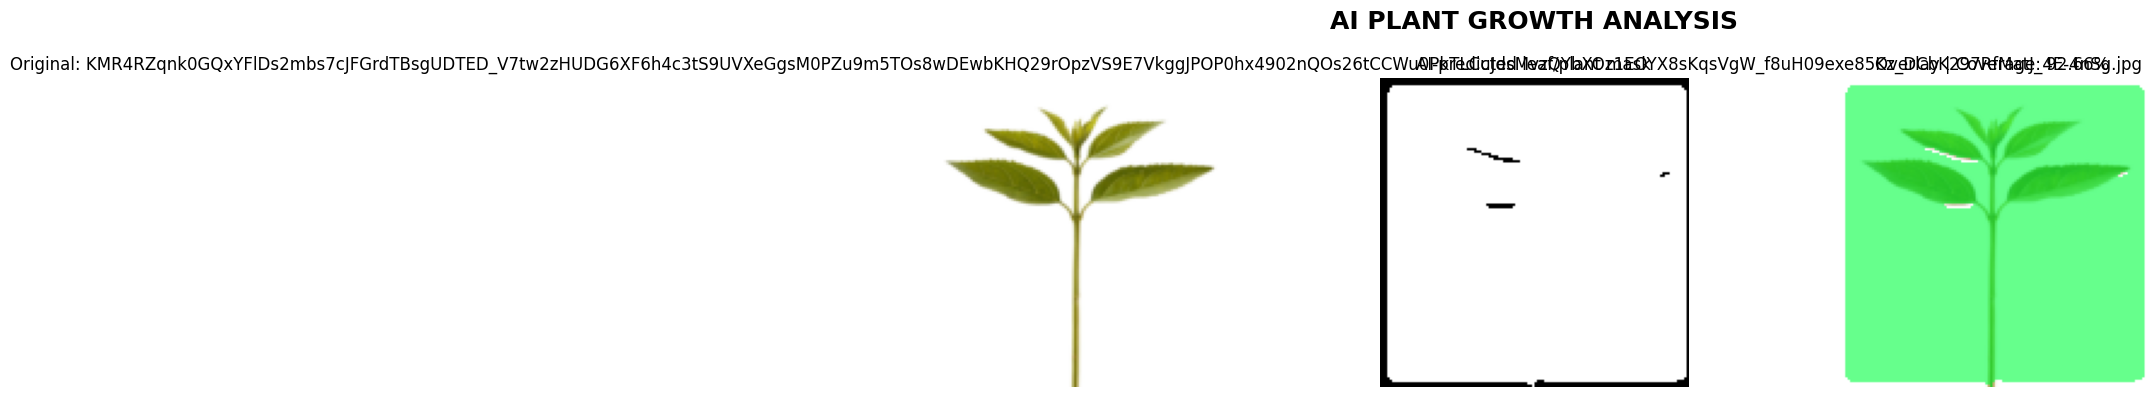

,Image,Date,Predicted coverage (%)
0,KMR4RZqnk0GQxYFlDs2mbs7cJFGrdTBsgUDTED_V7tw2zH...,Date not provided,92.66



GROWTH INTERPRETATION
Upload another image of the same plant from a different date
to compare visible leaf-area changes.


In [16]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch, re, os
from datetime import datetime

# Reuse the trained model from the previous cells
model.eval()
uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Please upload at least one plant image.")

results = []

for filename in uploaded:
    original = Image.open(filename).convert("RGB")
    resized = original.resize((128, 128), Image.Resampling.BILINEAR)
    arr = np.asarray(resized, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        prob = torch.sigmoid(model(tensor))[0, 0].cpu().numpy()

    pred = prob >= 0.5
    coverage = pred.mean() * 100

    # Read date from filename if formatted YYYY-MM-DD or YYYY_MM_DD
    match = re.search(r"(20\d{2})[-_](\d{2})[-_](\d{2})", filename)
    date = pd.to_datetime(
        "-".join(match.groups()) if match else None,
        errors="coerce"
    )

    overlay = arr.copy()
    overlay[pred] = (
        0.4 * overlay[pred] + 0.6 * np.array([0, 1, 0.25])
    ).clip(0, 1)

    results.append({
        "filename": filename,
        "date": date,
        "image": arr,
        "mask": pred,
        "overlay": overlay,
        "coverage": coverage,
        "confidence": float(prob[pred].mean()) if pred.any() else 0.0
    })

# Sort by date when filenames contain dates; otherwise use upload order
if all(pd.notna(r["date"]) for r in results):
    results.sort(key=lambda r: r["date"])

# Detailed image dashboard
fig, axes = plt.subplots(len(results), 3,
                         figsize=(14, 4 * len(results)))
if len(results) == 1:
    axes = np.array([axes])

for i, r in enumerate(results):
    axes[i, 0].imshow(r["image"])
    axes[i, 0].set_title("Original: " + r["filename"])
    axes[i, 1].imshow(r["mask"], cmap="gray")
    axes[i, 1].set_title("AI-predicted leaf/plant mask")
    axes[i, 2].imshow(r["overlay"])
    axes[i, 2].set_title(f"Overlay | Coverage: {r['coverage']:.2f}%")
    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("AI PLANT GROWTH ANALYSIS", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

# Measurement table
table = pd.DataFrame([{
    "Image": r["filename"],
    "Date": r["date"].strftime("%Y-%m-%d")
            if pd.notna(r["date"]) else "Date not provided",
    "Predicted coverage (%)": round(r["coverage"], 2)
} for r in results])

display(table)

# Explain change between earliest and latest measurement
first, last = results[0], results[-1]
change = last["coverage"] - first["coverage"]

print("\n" + "=" * 55)
print("GROWTH INTERPRETATION")
print("=" * 55)

if len(results) < 2:
    print("Upload another image of the same plant from a different date")
    print("to compare visible leaf-area changes.")
else:
    print(f"Starting visible coverage: {first['coverage']:.2f}%")
    print(f"Latest visible coverage:   {last['coverage']:.2f}%")
    print(f"Change in coverage:        {change:+.2f} percentage points")

    if change > 1:
        print("\nInterpretation: The model measured increased visible plant")
        print("coverage in the later image, consistent with foliage expansion.")
    elif change < -1:
        print("\nInterpretation: The model measured decreased visible plant")
        print("coverage. This could reflect leaf loss, wilting, camera angle,")
        print("lighting, or segmentation errors.")
    else:
        print("\nInterpretation: Visible plant coverage changed very little.")
        print("The images do not show a clear change in measured coverage.")

    print("\nLIMITATIONS")
    print("- Coverage is the percentage of the resized image classified as plant.")
    print("- This model predicts plant foreground, not individual leaf count.")
    print("- Differences in camera distance, angle, and lighting affect comparison.")
    print("- These measurements alone cannot diagnose plant health.")


Saving cb92129d-eede-45ac-97a6-569daa3e0e53.png to cb92129d-eede-45ac-97a6-569daa3e0e53.png


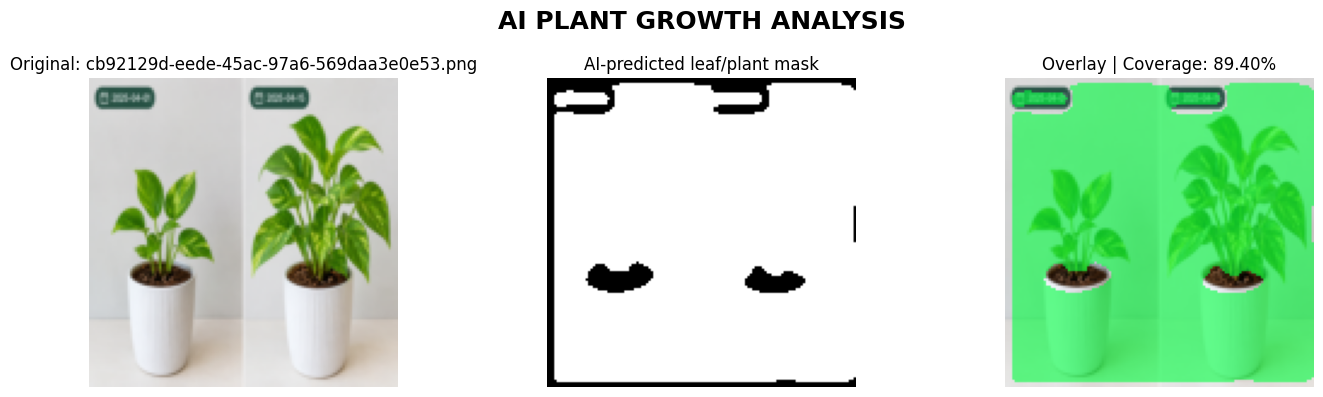

,Image,Date,Predicted coverage (%)
0,cb92129d-eede-45ac-97a6-569daa3e0e53.png,Date not provided,89.4



GROWTH INTERPRETATION
Upload another image of the same plant from a different date
to compare visible leaf-area changes.


In [17]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch, re, os
from datetime import datetime

# Reuse the trained model from the previous cells
model.eval()
uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Please upload at least one plant image.")

results = []

for filename in uploaded:
    original = Image.open(filename).convert("RGB")
    resized = original.resize((128, 128), Image.Resampling.BILINEAR)
    arr = np.asarray(resized, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        prob = torch.sigmoid(model(tensor))[0, 0].cpu().numpy()

    pred = prob >= 0.5
    coverage = pred.mean() * 100

    # Read date from filename if formatted YYYY-MM-DD or YYYY_MM_DD
    match = re.search(r"(20\d{2})[-_](\d{2})[-_](\d{2})", filename)
    date = pd.to_datetime(
        "-".join(match.groups()) if match else None,
        errors="coerce"
    )

    overlay = arr.copy()
    overlay[pred] = (
        0.4 * overlay[pred] + 0.6 * np.array([0, 1, 0.25])
    ).clip(0, 1)

    results.append({
        "filename": filename,
        "date": date,
        "image": arr,
        "mask": pred,
        "overlay": overlay,
        "coverage": coverage,
        "confidence": float(prob[pred].mean()) if pred.any() else 0.0
    })

# Sort by date when filenames contain dates; otherwise use upload order
if all(pd.notna(r["date"]) for r in results):
    results.sort(key=lambda r: r["date"])

# Detailed image dashboard
fig, axes = plt.subplots(len(results), 3,
                         figsize=(14, 4 * len(results)))
if len(results) == 1:
    axes = np.array([axes])

for i, r in enumerate(results):
    axes[i, 0].imshow(r["image"])
    axes[i, 0].set_title("Original: " + r["filename"])
    axes[i, 1].imshow(r["mask"], cmap="gray")
    axes[i, 1].set_title("AI-predicted leaf/plant mask")
    axes[i, 2].imshow(r["overlay"])
    axes[i, 2].set_title(f"Overlay | Coverage: {r['coverage']:.2f}%")
    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("AI PLANT GROWTH ANALYSIS", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

# Measurement table
table = pd.DataFrame([{
    "Image": r["filename"],
    "Date": r["date"].strftime("%Y-%m-%d")
            if pd.notna(r["date"]) else "Date not provided",
    "Predicted coverage (%)": round(r["coverage"], 2)
} for r in results])

display(table)

# Explain change between earliest and latest measurement
first, last = results[0], results[-1]
change = last["coverage"] - first["coverage"]

print("\n" + "=" * 55)
print("GROWTH INTERPRETATION")
print("=" * 55)

if len(results) < 2:
    print("Upload another image of the same plant from a different date")
    print("to compare visible leaf-area changes.")
else:
    print(f"Starting visible coverage: {first['coverage']:.2f}%")
    print(f"Latest visible coverage:   {last['coverage']:.2f}%")
    print(f"Change in coverage:        {change:+.2f} percentage points")

    if change > 1:
        print("\nInterpretation: The model measured increased visible plant")
        print("coverage in the later image, consistent with foliage expansion.")
    elif change < -1:
        print("\nInterpretation: The model measured decreased visible plant")
        print("coverage. This could reflect leaf loss, wilting, camera angle,")
        print("lighting, or segmentation errors.")
    else:
        print("\nInterpretation: Visible plant coverage changed very little.")
        print("The images do not show a clear change in measured coverage.")

    print("\nLIMITATIONS")
    print("- Coverage is the percentage of the resized image classified as plant.")
    print("- This model predicts plant foreground, not individual leaf count.")
    print("- Differences in camera distance, angle, and lighting affect comparison.")
    print("- These measurements alone cannot diagnose plant health.")


In [1]:

# STEP 1: Inspect the existing training data — no changes made

print("Number of training pairs:", len(pairs))
print("Device:", device)
print("Model type:", type(model).__name__)

if len(pairs) > 0:
    print("\nFirst training pair type:", type(pairs[0]))
    print("First training pair contents:", repr(pairs[0])[:1000])

print("\nSaved model exists:",
      __import__("os").path.exists(
          "/content/plant_growth_model/plant_unet_quick.pth"
      ))


NameError: name 'pairs' is not defined

In [2]:

# Inspect existing Colab variables without changing anything
import os

print("Relevant variables:")
for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "model", "train", "mask", "image", "data", "dataset",
        "pair", "path", "loader", "transform", "device"
    ]):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

print("\nModel file exists:",
      os.path.exists("/content/plant_growth_model/plant_unet_quick.pth"))

print("\nFiles in /content/plant_growth_model:")
folder = "/content/plant_growth_model"
if os.path.exists(folder):
    print(os.listdir(folder))


Relevant variables:
__loader__: NoneType

Model file exists: False

Files in /content/plant_growth_model:


In [3]:

import os

# Check Colab storage and common Google Drive locations
for root in ["/content", "/content/drive/MyDrive"]:
    print(f"\n--- {root} ---")
    if os.path.isdir(root):
        for current, dirs, files in os.walk(root):
            # Avoid scanning large dependency folders
            dirs[:] = [d for d in dirs if d not in {
                ".git", "node_modules", ".cache"
            }]
            for f in files:
                if f.lower().endswith((
                    ".pth", ".pt", ".h5", ".keras",
                    ".ipynb", ".zip"
                )):
                    print(os.path.join(current, f))
            # Keep the search manageable
            if current[len(root):].count(os.sep) >= 4:
                dirs[:] = []



--- /content ---

--- /content/drive/MyDrive ---


Upload the EARLIER photo of your plant.


Saving p1.png to p1.png
Loaded: p1.png | Size: (1086, 1448)
Now upload the LATER photo of the same plant.


Saving p2.png to p2.png
Loaded: p2.png | Size: (1086, 1448)


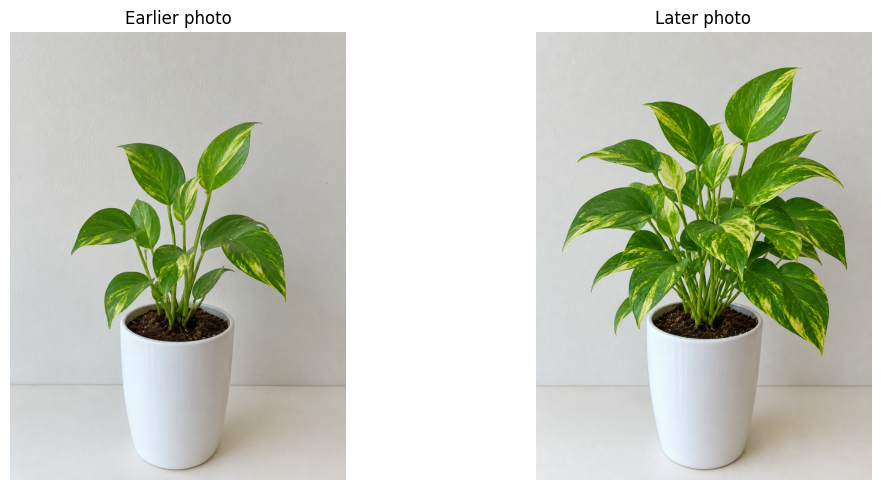

In [5]:

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

def upload_one(prompt):
    print(prompt)
    uploaded = files.upload()

    if len(uploaded) != 1:
        raise ValueError("Please upload exactly one image.")

    filename = next(iter(uploaded))
    img = Image.open(filename).convert("RGB")
    print("Loaded:", filename, "| Size:", img.size)
    return img

early_image = upload_one("Upload the EARLIER photo of your plant.")
late_image = upload_one("Now upload the LATER photo of the same plant.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(early_image)
axes[0].set_title("Earlier photo")
axes[1].imshow(late_image)
axes[1].set_title("Later photo")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


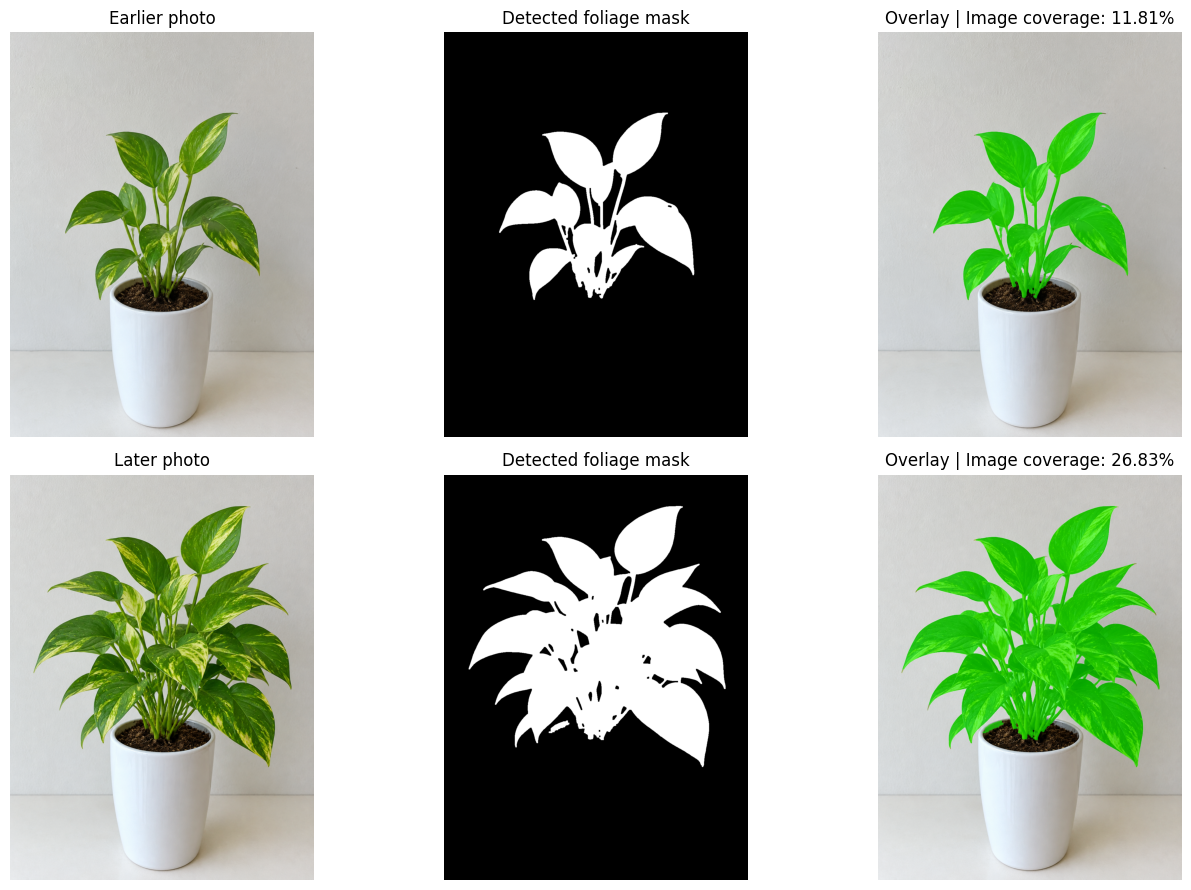

========== PLANT GROWTH REPORT ==========
Earlier detected foliage: 185,659 pixels
Later detected foliage:   421,890 pixels
Pixel change: +236,231
Relative detected-pixel change: +127.24%

IMPORTANT: These are color-based estimates, not verified leaf-area measurements.
Check both masks above. If they include background or miss leaves, do not trust the percentages.


In [6]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

def analyze_plant(img, label):
    # Convert PIL image to RGB array
    rgb = np.array(img.convert("RGB"))
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

    # Detect green foliage; baseline only, not a trained model
    mask = cv2.inRange(
        hsv,
        np.array([25, 35, 25], dtype=np.uint8),
        np.array([100, 255, 255], dtype=np.uint8)
    )

    # Remove small isolated noise
    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    # Keep connected regions likely to be foliage
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )
    clean = np.zeros_like(mask)
    for i in range(1, count):
        if stats[i, cv2.CC_STAT_AREA] >= 80:
            clean[labels == i] = 255

    foliage_pixels = int(np.count_nonzero(clean))
    total_pixels = clean.size
    coverage = 100 * foliage_pixels / total_pixels

    # Green overlay for visual inspection
    overlay = rgb.copy()
    overlay[clean > 0] = (
        0.45 * overlay[clean > 0] +
        0.55 * np.array([0, 255, 0])
    ).astype(np.uint8)

    return {
        "label": label,
        "mask": clean,
        "overlay": overlay,
        "foliage_pixels": foliage_pixels,
        "coverage": coverage
    }

early = analyze_plant(early_image, "Earlier")
late = analyze_plant(late_image, "Later")

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for row, result, original in [
    (0, early, early_image),
    (1, late, late_image)
]:
    axes[row, 0].imshow(original)
    axes[row, 0].set_title(result["label"] + " photo")

    axes[row, 1].imshow(result["mask"], cmap="gray")
    axes[row, 1].set_title("Detected foliage mask")

    axes[row, 2].imshow(result["overlay"])
    axes[row, 2].set_title(
        f'Overlay | Image coverage: {result["coverage"]:.2f}%'
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

change = late["foliage_pixels"] - early["foliage_pixels"]
if early["foliage_pixels"] > 0:
    growth = 100 * change / early["foliage_pixels"]
else:
    growth = None

print("========== PLANT GROWTH REPORT ==========")
print(f'Earlier detected foliage: {early["foliage_pixels"]:,} pixels')
print(f'Later detected foliage:   {late["foliage_pixels"]:,} pixels')
print(f"Pixel change: {change:+,}")

if growth is not None:
    print(f"Relative detected-pixel change: {growth:+.2f}%")
else:
    print("Growth change unavailable: no foliage detected in earlier image.")

print("\nIMPORTANT: These are color-based estimates, not verified leaf-area measurements.")
print("Check both masks above. If they include background or miss leaves, do not trust the percentages.")


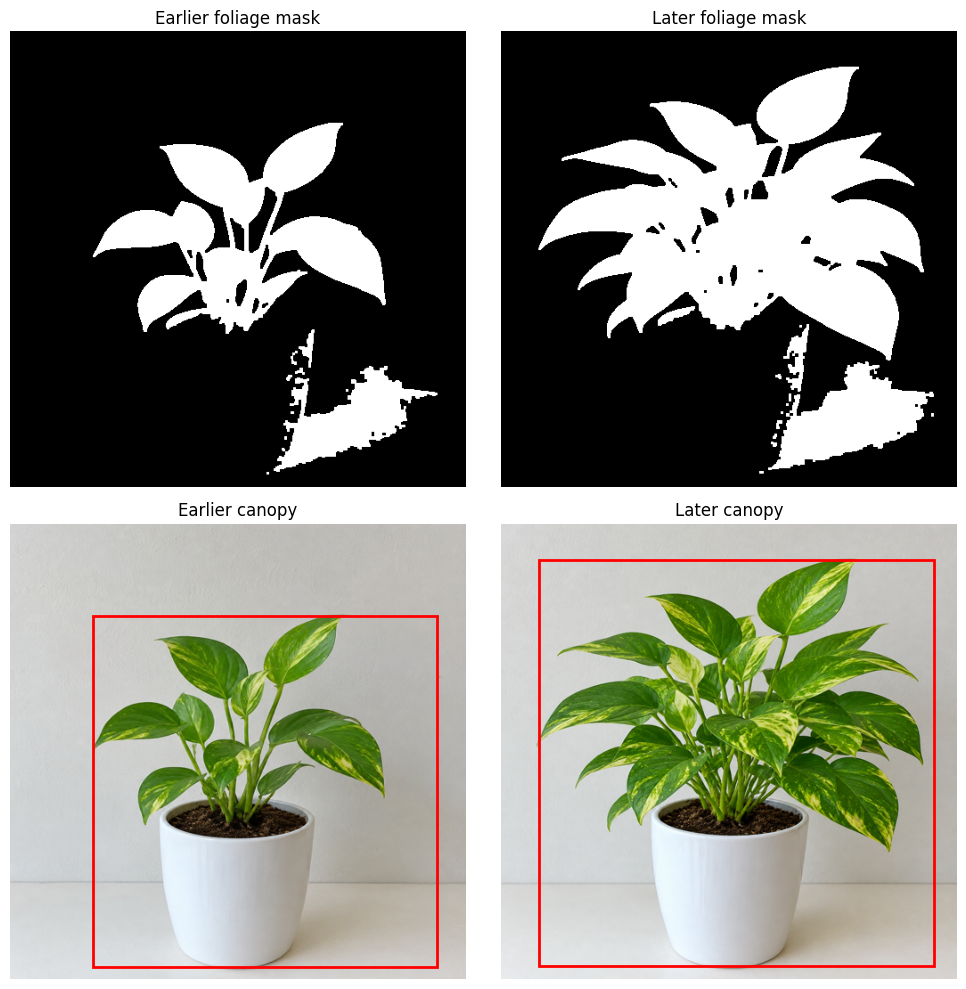

========== GROWTH DASHBOARD ==========
Earlier foliage coverage: 15.73%
Later foliage coverage:   31.86%
Detected pixel change:    +102.59%
Earlier canopy width:     387 px
Later canopy width:       444 px
Earlier canopy height:    395 px
Later canopy height:      457 px


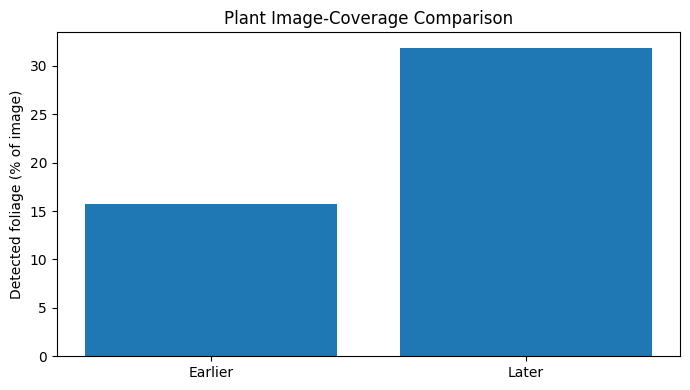

Note: Color-based estimates only. Inspect masks before interpreting growth.


In [7]:

import numpy as np
import matplotlib.pyplot as plt
import cv2

def improved_mask(pil_img):
    rgb = np.array(pil_img.convert("RGB"))
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

    # Broader range to include green and yellow-green leaves
    mask = cv2.inRange(
        hsv,
        np.array([18, 25, 25], dtype=np.uint8),
        np.array([100, 255, 255], dtype=np.uint8)
    )

    # Remove tiny noise while preserving leaf regions
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    return rgb, mask

def plant_metrics(pil_img):
    rgb, mask = improved_mask(pil_img)
    h, w = mask.shape
    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return None

    # Bounding rectangle of detected foliage
    x0, x1 = xs.min(), xs.max()
    y0, y1 = ys.min(), ys.max()

    area = len(xs)
    return {
        "rgb": rgb,
        "mask": mask,
        "area": area,
        "coverage": 100 * area / (h * w),
        "width": x1 - x0 + 1,
        "height": y1 - y0 + 1,
        "bbox": (x0, y0, x1, y1),
        "canopy_fraction": 100 * area /
            max(1, (x1 - x0 + 1) * (y1 - y0 + 1))
    }

# Normalize image dimensions before comparing pixel counts
common_size = (512, 512)
early_resized = early_image.resize(common_size)
late_resized = late_image.resize(common_size)

early_m = plant_metrics(early_resized)
late_m = plant_metrics(late_resized)

if early_m is None or late_m is None:
    raise ValueError("No foliage detected. Adjust the color thresholds.")

# Show both masks and bounding boxes for inspection
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, result, title in [
    (axes[0, 0], early_m, "Earlier foliage mask"),
    (axes[0, 1], late_m, "Later foliage mask")
]:
    ax.imshow(result["mask"], cmap="gray")
    ax.set_title(title)
    ax.axis("off")

for ax, result, title in [
    (axes[1, 0], early_m, "Earlier canopy"),
    (axes[1, 1], late_m, "Later canopy")
]:
    x0, y0, x1, y1 = result["bbox"]
    ax.imshow(result["rgb"])
    ax.add_patch(plt.Rectangle(
        (x0, y0), x1-x0+1, y1-y0+1,
        fill=False, edgecolor="red", linewidth=2
    ))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Growth metrics
area_change = late_m["area"] - early_m["area"]
relative_change = 100 * area_change / max(1, early_m["area"])

print("========== GROWTH DASHBOARD ==========")
print(f'Earlier foliage coverage: {early_m["coverage"]:.2f}%')
print(f'Later foliage coverage:   {late_m["coverage"]:.2f}%')
print(f'Detected pixel change:    {relative_change:+.2f}%')
print(f'Earlier canopy width:     {early_m["width"]} px')
print(f'Later canopy width:       {late_m["width"]} px')
print(f'Earlier canopy height:    {early_m["height"]} px')
print(f'Later canopy height:      {late_m["height"]} px')

plt.figure(figsize=(7, 4))
plt.bar(
    ["Earlier", "Later"],
    [early_m["coverage"], late_m["coverage"]]
)
plt.ylabel("Detected foliage (% of image)")
plt.title("Plant Image-Coverage Comparison")
plt.tight_layout()
plt.show()

print("Note: Color-based estimates only. Inspect masks before interpreting growth.")
